<a href="https://colab.research.google.com/github/Wahdaapf/PCVK_Ganjil_2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

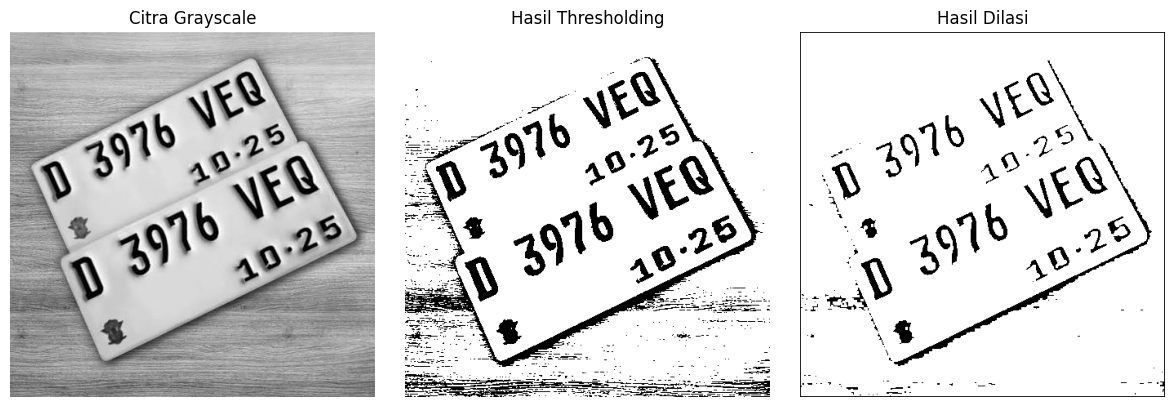

In [ ]:
# Dilasi tanpa library morfologi
def dilasi_citra(F, w):
    # Ukuran citra
    p, q = F.shape

    # Membuat citra hasil dengan nilai awal 0
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structuring Element Dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)

    # Menentukan titik tengah SED
    constant1 = (w - 1) // 2

    # Proses dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1 : i + constant1 + 1,
                j - constant1 : j + constant1 + 1
            ]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# Membaca citra grayscale
img_d = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    cv2.IMREAD_GRAYSCALE
)

# Memastikan citra berhasil dibaca
if img_d is None:
    raise FileNotFoundError("Citra plat.jpg tidak ditemukan!")

# Proses thresholding
ret, thresh = cv2.threshold(
    img_d, 125, 200, cv2.THRESH_BINARY
)

# Proses dilasi dengan ukuran kernel 3x3
img_hasil = dilasi_citra(thresh, 3)

# Menampilkan hasil
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Grayscale')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Hasil Thresholding')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_hasil, cmap='gray')
plt.title('Hasil Dilasi')
plt.axis('off')

plt.tight_layout()
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


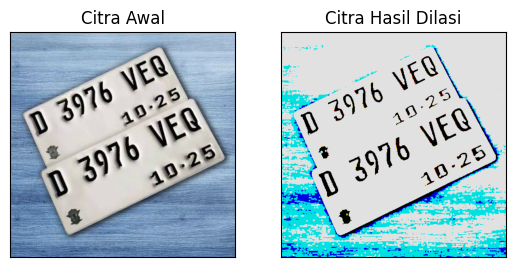

In [ ]:
img = cv2.imread('/content/drive/MyDrive/Google Collab/plat.jpg')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

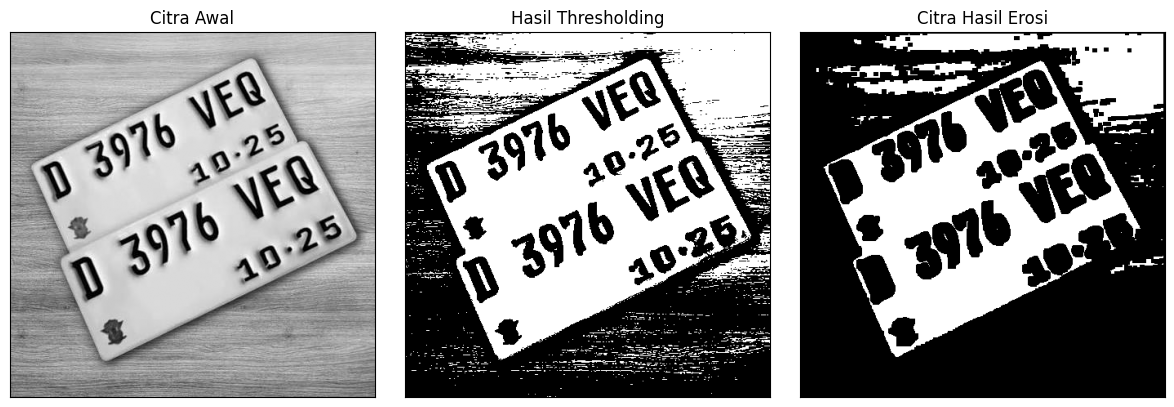

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Erosi Tanpa Library
def erosi_citra(F, k):
    # Size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    # Membuat citra hasil erosi
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant : i + constant + 1,
                j - constant : j + constant + 1
            ]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# Membaca citra grayscale
img_e = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    cv2.IMREAD_GRAYSCALE
)

# Memastikan citra berhasil dibaca
if img_e is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret1, thresh1 = cv2.threshold(
    img_e, 175, 225, cv2.THRESH_BINARY
)

# Proses erosi dengan kernel 5x5
k = 5
imgE = erosi_citra(thresh1, k)

# Menampilkan hasil
plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(thresh1, cmap='gray')
plt.title('Hasil Thresholding')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

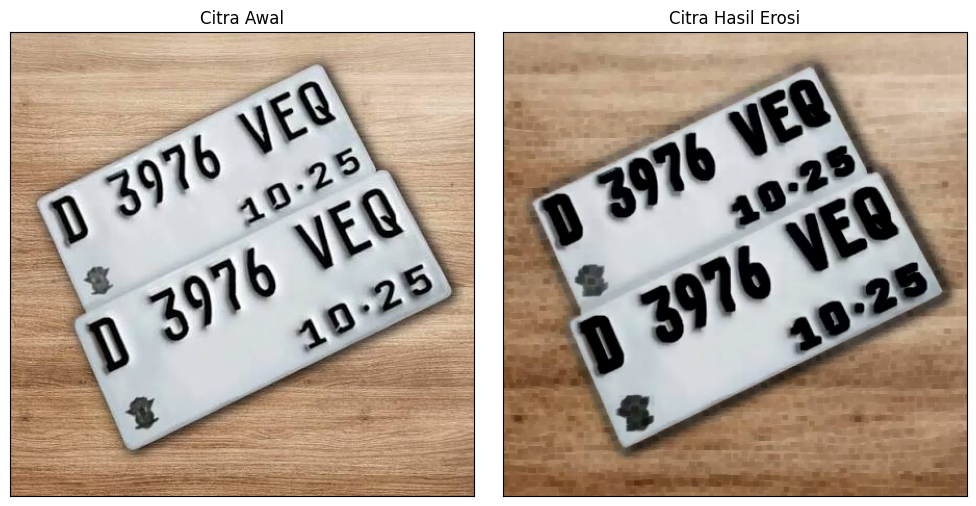

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra
img = cv2.imread('/content/drive/MyDrive/Google Collab/plat.jpg')

# Memastikan citra berhasil dibaca
if img is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Membuat kernel 5x5
kernel = np.ones((5, 5), np.uint8)

# Proses erosi menggunakan library OpenCV
erosion = cv2.erode(img, kernel, iterations=1)

# Konversi BGR ke RGB agar warna tampil benar di Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
erosion_rgb = cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB)

# Menampilkan citra awal
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil erosi
plt.subplot(122)
plt.imshow(erosion_rgb)
plt.title('Citra Hasil Erosi')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

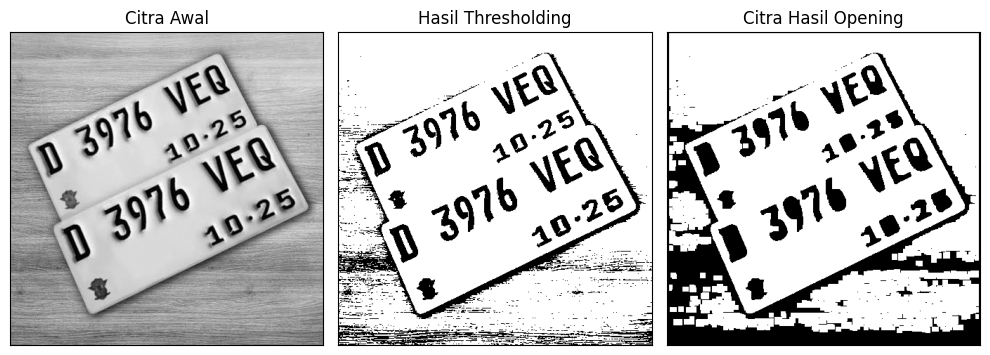

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra grayscale
img_o = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    cv2.IMREAD_GRAYSCALE
)

# Memastikan citra berhasil dibaca
if img_o is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
ret, thresh_o = cv2.threshold(
    img_o, 127, 225, cv2.THRESH_BINARY
)

# Ukuran kernel
k = 7

# Proses Opening: Erosi dilanjutkan dengan Dilasi
imgO = dilasi_citra(erosi_citra(thresh_o, k), k)

# Menampilkan citra awal
plt.figure(figsize=(10, 5))

plt.subplot(131)
plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil thresholding
plt.subplot(132)
plt.imshow(thresh_o, cmap='gray')
plt.title('Hasil Thresholding')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil opening
plt.subplot(133)
plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

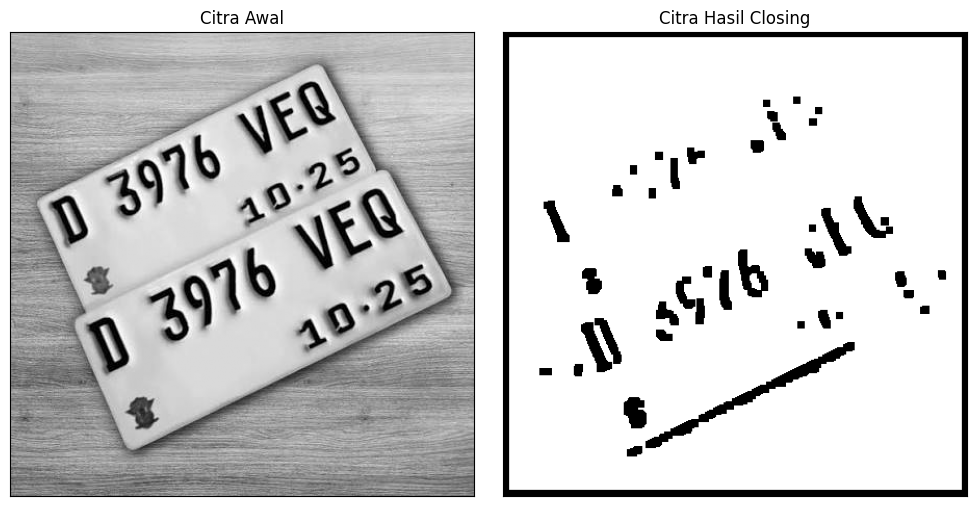

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra grayscale
img_c = cv2.imread(
    '/content/drive/MyDrive/Google Collab/plat.jpg',
    0
)

# Memastikan citra berhasil dibaca
if img_c is None:
    raise FileNotFoundError("File plat nomer.jpg tidak ditemukan!")

# Thresholding
retc, threshc = cv2.threshold(
    img_c, 127, 225, cv2.THRESH_BINARY
)

# Ukuran kernel
k = 7

# Proses Closing: Dilasi dilanjutkan dengan Erosi
imgC = erosi_citra(dilasi_citra(threshc, k), k)

# Menampilkan citra awal
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal')
plt.xticks([])
plt.yticks([])

# Menampilkan hasil closing
plt.subplot(122)
plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()